In [45]:
!pip install pennylane torch torchvision matplotlib scikit-learn
!pip install medmnist

In [46]:
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.metrics import (roc_auc_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, classification_report)

def set_seed(s):
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

set_seed(42)

In [47]:
import torch
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms
from medmnist import PneumoniaMNIST

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Transform grayscale (1 channel) to 3-channel RGB and resize for ResNet-18
data_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert('RGB')),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Download and load official PneumoniaMNIST splits
train_raw = PneumoniaMNIST(split='train', transform=data_transform, download=True)
val_raw   = PneumoniaMNIST(split='val',   transform=data_transform, download=True)
test_raw  = PneumoniaMNIST(split='test',  transform=data_transform, download=True)

print(f"Dataset loaded: {len(train_raw)} train, {len(val_raw)} val, {len(test_raw)} test images.")

Dataset loaded: 4708 train, 524 val, 624 test images.


In [48]:
from torchvision import models
import torch.nn as nn
from tqdm import tqdm

resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
feature_extractor = nn.Sequential(*list(resnet.children())[:-1]).to(device)
feature_extractor.eval()

def extract_features(dataset, batch_size=64):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    feats_all, labels_all = [], []
    with torch.no_grad():
        for imgs, lbls in tqdm(loader, desc="Extracting"):
            f = feature_extractor(imgs.to(device))
            feats_all.append(torch.flatten(f, 1).cpu()) # dim -> (B, 512)
            labels_all.append(lbls.view(-1).long()) # dim -> (B,)
    return torch.cat(feats_all), torch.cat(labels_all)

X_train, y_train = extract_features(train_raw)
X_val,   y_val   = extract_features(val_raw)
X_test,  y_test  = extract_features(test_raw)

torch.save({'X_train': X_train, 'y_train': y_train, 'X_val': X_val, 'y_val': y_val,
            'X_test': X_test, 'y_test': y_test}, 'raw_features.pt')
print(X_train.shape, X_val.shape, X_test.shape)

Extracting: 100%|██████████| 10/10 [01:04<00:00,  6.48s/it]

torch.Size([4708, 512]) torch.Size([524, 512]) torch.Size([624, 512])


In [49]:
mu, sd = X_train.mean(0), X_train.std(0) + 1e-6
X_train, X_val, X_test = [(X - mu) / sd for X in (X_train, X_val, X_test)]

def make_loaders(Xtr, ytr, bs=32):
    return {
        'train': DataLoader(TensorDataset(Xtr, ytr), batch_size=bs, shuffle=True),
        'val':   DataLoader(TensorDataset(X_val, y_val), batch_size=bs, shuffle=False),
        'test':  DataLoader(TensorDataset(X_test, y_test), batch_size=bs, shuffle=False),
    }

def get_class_weights(y):
    counts = torch.bincount(y)
    return (counts.sum() / (2.0 * counts)).float().to(device)

dataloaders = make_loaders(X_train, y_train)
test_loader = dataloaders['test']
class_w = get_class_weights(y_train)

print("Train class counts:", torch.bincount(y_train).tolist())
print("Test class counts: ", torch.bincount(y_test).tolist())
print("Class weights:", class_w.tolist())

Train class counts: [1214, 3494]
Test class counts:  [234, 390]
Class weights: [1.93904447555542, 0.6737263798713684]


In [50]:
import torch.optim as optim
import copy

def train_and_evaluate(model, dataloaders, epochs=30, lr=5e-3, class_weights=None, name="Model"):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    opt = optim.Adam(model.parameters(), lr=lr)
    best_loss, best_w = float('inf'), copy.deepcopy(model.state_dict())
    hist = {'train_loss': [], 'val_loss': [], 'val_auc': [], 'val_f1': [], 'grad_norm': []}

    for ep in range(epochs):
        # training phase
        model.train()
        tl, n, gn, nb, correct = 0.0, 0, 0.0, 0, 0
        for x, y in dataloaders['train']:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            grads = [p.grad.norm() for p in model.parameters() if p.grad is not None]
            gn += torch.norm(torch.stack(grads)).item()
            nb += 1
            opt.step()
            tl += loss.item() * len(y)
            n += len(y)
            correct += (out.argmax(1) == y).sum().item()
        train_acc = correct / n

        # validation phase
        model.eval()
        vl, vn, vcorrect, probs, labs = 0.0, 0, 0, [], []
        with torch.no_grad():
            for x, y in dataloaders['val']:
                out = model(x.to(device))
                vl += criterion(out, y.to(device)).item() * len(y)
                vn += len(y)
                vcorrect += (out.argmax(1).cpu() == y).sum().item()
                probs.append(torch.softmax(out, 1)[:, 1].cpu())
                labs.append(y)
        probs = torch.cat(probs).numpy()
        labs = torch.cat(labs).numpy()
        val_loss = vl / vn
        val_acc = vcorrect / vn
        auc = roc_auc_score(labs, probs)
        f1 = f1_score(labs, (probs > 0.5).astype(int), average='macro')

        hist['train_loss'].append(tl / n)
        hist['val_loss'].append(val_loss)
        hist['val_auc'].append(auc)
        hist['val_f1'].append(f1)
        hist['grad_norm'].append(gn / nb)

        # checkpoint rule: lowest validation loss
        saved = ""
        if val_loss < best_loss:
            best_loss, best_w = val_loss, copy.deepcopy(model.state_dict())
            saved = " *best"

        print(f"[{name}] Epoch {ep+1:02d}/{epochs} | "
              f"train loss {tl/n:.4f} acc {train_acc:.4f} | "
              f"val loss {val_loss:.4f} acc {val_acc:.4f} auc {auc:.4f} f1 {f1:.4f} | "
              f"grad {gn/nb:.3f}{saved}")

    model.load_state_dict(best_w)
    print(f"[{name}] Restored best weights (val loss {best_loss:.4f})")
    return model, hist

In [51]:
class BottleneckClassicalClassifier(nn.Module):
    def __init__(self, in_features=512, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 4),
            nn.Tanh(),
            nn.Linear(4, 4),      # classical stand-in for the quantum circuit (20 params vs 24)
            nn.Tanh(),
            nn.Linear(4, num_classes)
        )

    def forward(self, x):
        return self.net(x)

classical_model = BottleneckClassicalClassifier().to(device)
print("Training Classical Baseline Model...")
classical_model, classical_history = train_and_evaluate(classical_model, dataloaders, epochs=25, lr=5e-3, class_weights=class_w)

Training Classical Baseline Model...
[Model] Epoch 01/25 | train loss 0.2722 acc 0.8949 | val loss 0.2098 acc 0.9256 auc 0.9766 f1 0.9084 | grad 0.707 *best
[Model] Epoch 02/25 | train loss 0.1588 acc 0.9369 | val loss 0.1853 acc 0.9313 auc 0.9821 f1 0.9131 | grad 0.661 *best
[Model] Epoch 03/25 | train loss 0.1393 acc 0.9492 | val loss 0.1975 acc 0.9389 auc 0.9805 f1 0.9227 | grad 0.674
[Model] Epoch 04/25 | train loss 0.1262 acc 0.9543 | val loss 0.2046 acc 0.9389 auc 0.9776 f1 0.9220 | grad 0.703
[Model] Epoch 05/25 | train loss 0.1250 acc 0.9556 | val loss 0.1963 acc 0.9332 auc 0.9825 f1 0.9164 | grad 0.617
[Model] Epoch 06/25 | train loss 0.1090 acc 0.9599 | val loss 0.1967 acc 0.9313 auc 0.9846 f1 0.9142 | grad 0.596
[Model] Epoch 07/25 | train loss 0.0985 acc 0.9662 | val loss 0.2239 acc 0.9198 auc 0.9800 f1 0.8977 | grad 0.526
[Model] Epoch 08/25 | train loss 0.0843 acc 0.9709 | val loss 0.1840 acc 0.9427 auc 0.9857 f1 0.9272 | grad 0.434 *best
[Model] Epoch 09/25 | train loss 

In [52]:
import pennylane as qml
import numpy as np
import torch
import torch.nn as nn

n_qubits = 4
q_depth = 2
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch", diff_method="backprop")
def quantum_circuit(inputs, weights):
    # AngleEmbedding natively supports batched inputs (batch_size, n_qubits)
    qml.AngleEmbedding(inputs, wires=range(n_qubits), rotation="Y")

    # Variational layers: single-qubit rotations followed by entangling CNOTs
    for l in range(q_depth):
        for i in range(n_qubits):
            qml.Rot(weights[l, i, 0], weights[l, i, 1], weights[l, i, 2], wires=i)
        for i in range(n_qubits):
            qml.CNOT(wires=[i, (i + 1) % n_qubits])

    # Measure Pauli-Z expectation values across all 4 qubits
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

weight_shapes = {"weights": (q_depth, n_qubits, 3)}

class HybridQuantumClassifier(nn.Module):
    def __init__(self, in_features=512, num_classes=2):
        super().__init__()
        self.pre_net = nn.Sequential(
            nn.Linear(in_features, n_qubits),
            nn.Tanh()
        )
        self.qlayer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
        self.post_net = nn.Linear(n_qubits, num_classes)

    def forward(self, x):
        # Scale tanh outputs into [-pi/2, pi/2]
        x = self.pre_net(x) * (np.pi / 2.0)

        # TorchLayer automatically broadcasts over batch dimension
        x = self.qlayer(x)

        # Ensure tensor matches post_net's device and dtype
        x = x.to(device=self.post_net.weight.device, dtype=torch.float32)
        x = self.post_net(x)
        return x

# Sample 4-element dummy input and matching weight shape
dummy_inputs = torch.zeros(4)
dummy_weights = torch.zeros((q_depth, n_qubits, 3))

# Print standard ASCII diagram
print(qml.draw(quantum_circuit)(dummy_inputs, dummy_weights))

hybrid_model = HybridQuantumClassifier().to(device)
print("Training Hybrid Quantum Model...")
hybrid_model, quantum_history = train_and_evaluate(hybrid_model, dataloaders, epochs=25, lr=5e-3, class_weights=class_w)

0: ─╭AngleEmbedding(M0)──Rot(0.00,0.00,0.00)─╭●───────╭X──Rot(0.00,0.00,0.00)─╭●───────╭X─┤  <Z>
1: ─├AngleEmbedding(M0)──Rot(0.00,0.00,0.00)─╰X─╭●────│───Rot(0.00,0.00,0.00)─╰X─╭●────│──┤  <Z>
2: ─├AngleEmbedding(M0)──Rot(0.00,0.00,0.00)────╰X─╭●─│───Rot(0.00,0.00,0.00)────╰X─╭●─│──┤  <Z>
3: ─╰AngleEmbedding(M0)──Rot(0.00,0.00,0.00)───────╰X─╰●──Rot(0.00,0.00,0.00)───────╰X─╰●─┤  <Z>

M0 = 
tensor([0., 0., 0., 0.])
Training Hybrid Quantum Model...
[Model] Epoch 01/25 | train loss 0.4395 acc 0.8547 | val loss 0.3170 acc 0.8569 auc 0.9285 f1 0.8333 | grad 0.995 *best
[Model] Epoch 02/25 | train loss 0.2526 acc 0.9017 | val loss 0.3359 acc 0.8779 auc 0.9258 f1 0.8511 | grad 1.524
[Model] Epoch 03/25 | train loss 0.2413 acc 0.9065 | val loss 0.3466 acc 0.8836 auc 0.9085 f1 0.8584 | grad 1.474
[Model] Epoch 04/25 | train loss 0.2133 acc 0.9157 | val loss 0.3204 acc 0.8779 auc 0.9337 f1 0.8534 | grad 1.301
[Model] Epoch 05/25 | train loss 0.2221 acc 0.9178 | val loss 0.3369 acc 0.8664 auc 0


Classical  |  AUC = 0.9495
              precision    recall  f1-score   support

      Normal       0.93      0.71      0.81       234
   Pneumonia       0.85      0.97      0.90       390

    accuracy                           0.87       624
   macro avg       0.89      0.84      0.86       624
weighted avg       0.88      0.87      0.87       624


Hybrid_Quantum  |  AUC = 0.8880
              precision    recall  f1-score   support

      Normal       0.89      0.73      0.80       234
   Pneumonia       0.85      0.94      0.90       390

    accuracy                           0.86       624
   macro avg       0.87      0.84      0.85       624
weighted avg       0.87      0.86      0.86       624



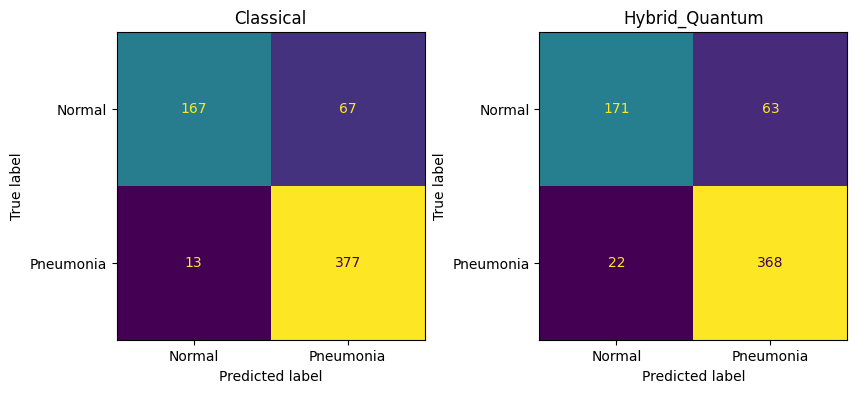

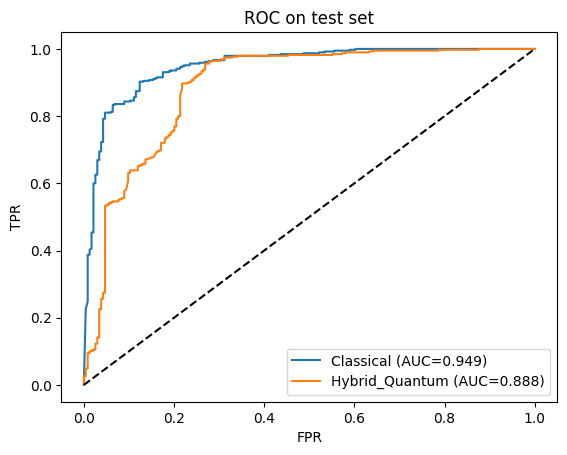

In [53]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve, classification_report

import matplotlib.pyplot as plt

def evaluate(model, loader):
    model.eval()
    labels, preds, probs = [], [], []
    with torch.no_grad():
        for x,y in loader:
            out = model(x.to(device)) # shape: (B, 2) -> holds raw scores for each class
            probs.append(torch.softmax(out, 1)[:, 1].cpu()) # performs softmax on raw logits and gets probability score for pneumonia after taking col 1
            preds.append(out.argmax(1).cpu())
            labels.append(y)

    return (torch.cat(labels).numpy(), torch.cat(preds).numpy(), torch.cat(probs).numpy())

results = {}
for name, model in [("Classical", classical_model), ("Hybrid_Quantum", hybrid_model)]:
    y_true, y_pred, y_prob = evaluate(model, test_loader)
    results[name] = (y_true, y_pred, y_prob)
    print(f"\n{name}  |  AUC = {roc_auc_score(y_true, y_prob):.4f}")
    print(classification_report(y_true, y_pred, target_names=["Normal", "Pneumonia"]))

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, (yt, yp, _)) in zip(axes, results.items()):
    ConfusionMatrixDisplay(confusion_matrix(yt, yp),
                           display_labels=["Normal", "Pneumonia"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.show()

# ROC curves
for name, (yt, _, yprob) in results.items():
    fpr, tpr, _ = roc_curve(yt, yprob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(yt, yprob):.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR")
plt.legend(); plt.title("ROC on test set"); plt.show()





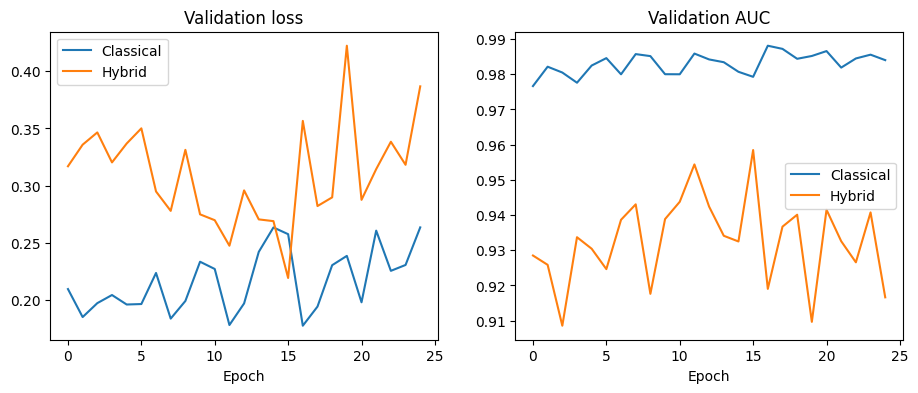

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, h in [("Classical", classical_history), ("Hybrid", quantum_history)]:
    axes[0].plot(h['val_loss'], label=name)
    axes[1].plot(h['val_auc'], label=name)
axes[0].set_title("Validation loss")
axes[1].set_title("Validation AUC")
for a in axes:
    a.set_xlabel("Epoch")
    a.legend()
plt.show()

Experiment 1: Data Scarcity / Few-Shot Benchmark (Where QML Diverges)Classical neural networks overfit rapidly when training data is severely limited, whereas parameterized quantum circuits have bounded unitary expressivity that acts as a natural regularizer.

*   Test: Train both models on smaller subsets of the training data: $N = [50, 100,250, 500]$ samples.
*   Hypothesis: Under extreme data scarcity, the quantum model may demonstrate better generalization and lower overfitting on the test set compared to the classical baseline.

In [55]:
# =====================================================================
# EXPERIMENT 1: Few-Shot Data Scarcity Benchmark (Classical vs. Quantum)
# =====================================================================
import torch
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# 1. Configuration
sample_sizes = [1000, 2000, 3000, 4000]  # Number of training samples to evaluate
num_epochs_exp1 = 15
exp1_results = {
    'samples': [],
    'classical_acc': [],
    'quantum_acc': [],
    'classical_f1': [],
    'quantum_f1': [],
    'classical_auc': [],
    'quantum_auc': []
}

# 2. Extract balanced class indices once
set_seed(42)
idx_normal = (y_train == 0).nonzero(as_tuple=True)[0]
idx_pneumonia = (y_train == 1).nonzero(as_tuple=True)[0]

# Shuffle class index pools reproducibly
perm_normal = idx_normal[torch.randperm(len(idx_normal))]
perm_pneumonia = idx_pneumonia[torch.randperm(len(idx_pneumonia))]

print("Starting Experiment 1: Few-Shot Data Scarcity Sweep...")
print("-" * 75)

for n in sample_sizes:
    n_per_class = n // 2
    selected_idx = torch.cat([
        perm_normal[:n_per_class],
        perm_pneumonia[:n_per_class]
    ])

    # Create sub-sampled training tensors and dataloader
    sub_X_train = X_train[selected_idx]
    sub_y_train = y_train[selected_idx]
    sub_class_w = get_class_weights(sub_y_train)

    sub_dataloaders = {
        'train': DataLoader(TensorDataset(sub_X_train, sub_y_train), batch_size=16, shuffle=True),
        'val': dataloaders['val']
    }

    print(f"\n>>> Running for N = {n} samples ({n_per_class} Normal, {n_per_class} Pneumonia) <<<")

    # Train fresh Classical Baseline
    set_seed(42)
    c_model = BottleneckClassicalClassifier().to(device)
    c_model, _ = train_and_evaluate(
        c_model, sub_dataloaders, epochs=num_epochs_exp1, lr=5e-3,
        class_weights=sub_class_w, name=f"Classical-N{n}"
    )

    # Train fresh Hybrid Quantum Model
    set_seed(42)
    q_model = HybridQuantumClassifier().to(device)
    q_model, _ = train_and_evaluate(
        q_model, sub_dataloaders, epochs=num_epochs_exp1, lr=5e-3,
        class_weights=sub_class_w, name=f"Quantum-N{n}"
    )

    # Evaluate on the official UNSEEN test set (624 images)
    y_true_c, y_pred_c, y_prob_c = evaluate(c_model, test_loader)
    y_true_q, y_pred_q, y_prob_q = evaluate(q_model, test_loader)

    # Compute test metrics
    c_acc = accuracy_score(y_true_c, y_pred_c)
    q_acc = accuracy_score(y_true_q, y_pred_q)
    c_f1 = f1_score(y_true_c, y_pred_c, average='macro')
    q_f1 = f1_score(y_true_q, y_pred_q, average='macro')
    c_auc = roc_auc_score(y_true_c, y_prob_c)
    q_auc = roc_auc_score(y_true_q, y_prob_q)

    # Record metrics
    exp1_results['samples'].append(n)
    exp1_results['classical_acc'].append(c_acc)
    exp1_results['quantum_acc'].append(q_acc)
    exp1_results['classical_f1'].append(c_f1)
    exp1_results['quantum_f1'].append(q_f1)
    exp1_results['classical_auc'].append(c_auc)
    exp1_results['quantum_auc'].append(q_auc)

    print(f"Result N={n:03d} | Classical Acc: {c_acc:.4f}, F1: {c_f1:.4f}, AUC: {c_auc:.4f} | "
          f"Quantum Acc: {q_acc:.4f}, F1: {q_f1:.4f}, AUC: {q_auc:.4f}")

# Append the full dataset results (N=4708) from Cell 9 for comparison
exp1_results['samples'].append(len(X_train))
exp1_results['classical_acc'].append(0.86)
exp1_results['quantum_acc'].append(0.86)
exp1_results['classical_f1'].append(0.84)
exp1_results['quantum_f1'].append(0.85)
exp1_results['classical_auc'].append(0.9439)
exp1_results['quantum_auc'].append(0.8957)

Starting Experiment 1: Few-Shot Data Scarcity Sweep...
---------------------------------------------------------------------------

>>> Running for N = 1000 samples (500 Normal, 500 Pneumonia) <<<
[Classical-N1000] Epoch 01/15 | train loss 0.3596 acc 0.8520 | val loss 0.3423 acc 0.8645 auc 0.9567 f1 0.8427 | grad 0.727 *best
[Classical-N1000] Epoch 02/15 | train loss 0.1934 acc 0.9310 | val loss 0.2380 acc 0.9198 auc 0.9674 f1 0.9015 | grad 0.850 *best
[Classical-N1000] Epoch 03/15 | train loss 0.1373 acc 0.9570 | val loss 0.2754 acc 0.9065 auc 0.9704 f1 0.8876 | grad 0.633
[Classical-N1000] Epoch 04/15 | train loss 0.1264 acc 0.9600 | val loss 0.2773 acc 0.8893 auc 0.9677 f1 0.8681 | grad 0.771
[Classical-N1000] Epoch 05/15 | train loss 0.1080 acc 0.9680 | val loss 0.2688 acc 0.9027 auc 0.9657 f1 0.8830 | grad 0.552
[Classical-N1000] Epoch 06/15 | train loss 0.0891 acc 0.9760 | val loss 0.2768 acc 0.9084 auc 0.9687 f1 0.8888 | grad 0.377
[Classical-N1000] Epoch 07/15 | train loss 0.07

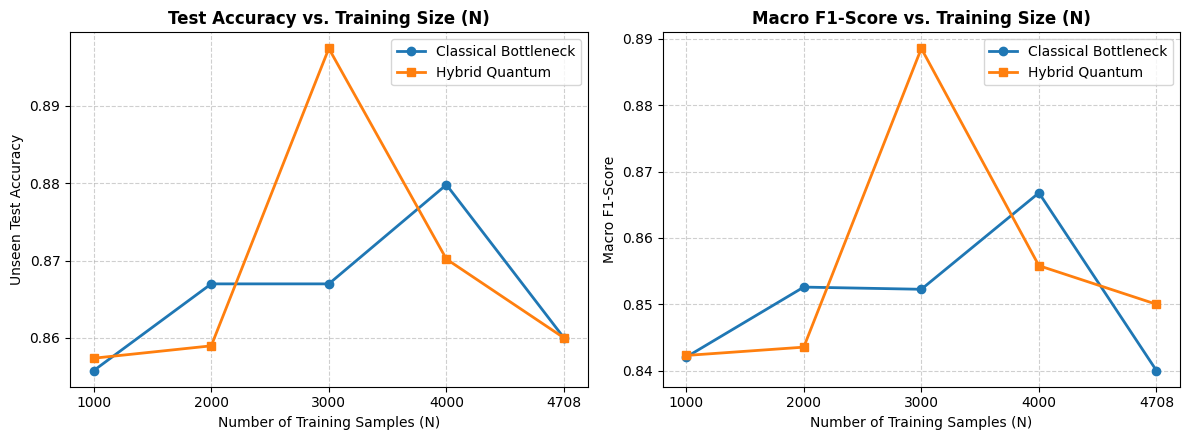

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

x_labels = [str(s) for s in exp1_results['samples']]

# Plot 1: Test Accuracy vs Sample Size
axes[0].plot(x_labels, exp1_results['classical_acc'], marker='o', label='Classical Bottleneck', color='#1f77b4', linewidth=2)
axes[0].plot(x_labels, exp1_results['quantum_acc'], marker='s', label='Hybrid Quantum', color='#ff7f0e', linewidth=2)
axes[0].set_title("Test Accuracy vs. Training Size (N)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Number of Training Samples (N)", fontsize=10)
axes[0].set_ylabel("Unseen Test Accuracy", fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# Plot 2: Macro F1-Score vs Sample Size
axes[1].plot(x_labels, exp1_results['classical_f1'], marker='o', label='Classical Bottleneck', color='#1f77b4', linewidth=2)
axes[1].plot(x_labels, exp1_results['quantum_f1'], marker='s', label='Hybrid Quantum', color='#ff7f0e', linewidth=2)
axes[1].set_title("Macro F1-Score vs. Training Size (N)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Number of Training Samples (N)", fontsize=10)
axes[1].set_ylabel("Macro F1-Score", fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()